<a href="https://colab.research.google.com/github/mena-04/Ananas/blob/main/classical_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and configurations

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

SEED = 42
N_FEATURES = 4
np.random.seed(SEED)


Loading the dataset

In [2]:

data = load_breast_cancer()

X = data.data
y = (data.target == 0).astype(int)

print("Dataset shape:", X.shape)
print("Malignant:", np.sum(y == 1))
print("Benign:", np.sum(y == 0))
print("Features:", len(data.feature_names))

df = pd.DataFrame(X, columns=data.feature_names)
df["malignant"] = y
display(df.head())


Dataset shape: (569, 30)
Malignant: 212
Benign: 357
Features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Shared data split

In [3]:

indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_raw = X[train_idx]
X_test_raw = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

np.savez(
    "shared_split.npz",
    train_idx=train_idx,
    test_idx=test_idx,
    y_train=y_train,
    y_test=y_test
)


Training samples: 455
Testing samples: 114


Shared preprocessing pipeline

In [4]:

def make_preprocessor(n_features=4):
    return Pipeline([
        ("standardize", StandardScaler()),
        ("pca", PCA(n_components=n_features)),
        ("angles", MinMaxScaler(
            feature_range=(0, np.pi),
            clip=True
        ))
    ])

preprocessor = make_preprocessor(N_FEATURES)

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train angle range:", X_train.min(), X_train.max())

np.savez(
    "shared_data.npz",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    train_idx=train_idx,
    test_idx=test_idx
)


Train shape: (455, 4)
Test shape: (114, 4)
Train angle range: 0.0 3.141592653589793


Tune the models

In [5]:

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

model_configs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10, 100]}
    ),
    "RBF SVM": (
        SVC(kernel="rbf"),
        {
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.1, 1, 10]
        }
    ),
    "Polynomial SVM": (
        SVC(kernel="poly"),
        {
            "model__C": [0.1, 1, 10],
            "model__degree": [2, 3],
            "model__gamma": ["scale", 1]
        }
    )
}

trained_models = {}
results = []

for name, (estimator, params) in model_configs.items():

    pipeline = Pipeline([
        ("preprocess", make_preprocessor(N_FEATURES)),
        ("model", estimator)
    ])

    search = GridSearchCV(
        pipeline,
        params,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        refit=True
    )

    start = time.perf_counter()
    search.fit(X_train_raw, y_train)
    elapsed = time.perf_counter() - start

    best = search.best_estimator_
    predictions = best.predict(X_test_raw)
    scores = best.decision_function(X_test_raw)

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, scores),
        "fit_and_tune_seconds": elapsed
    })

    trained_models[name] = best

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print("CV ROC-AUC:", round(search.best_score_, 4))

results_df = pd.DataFrame(results)
display(results_df.round(4))



Logistic Regression
Best parameters: {'model__C': 100}
CV ROC-AUC: 0.9894

RBF SVM
Best parameters: {'model__C': 10, 'model__gamma': 0.1}
CV ROC-AUC: 0.9916

Polynomial SVM
Best parameters: {'model__C': 1, 'model__degree': 2, 'model__gamma': 'scale'}
CV ROC-AUC: 0.9896


,model,accuracy,precision,recall,f1,roc_auc,fit_and_tune_seconds
0,Logistic Regression,0.9737,1.0,0.9286,0.9630,0.9980,6.6920
1,RBF SVM,0.9649,1.0,0.9048,0.9500,0.9977,1.4563
2,Polynomial SVM,0.9561,1.0,0.8810,0.9367,0.9974,0.8713


Save metrics and visualize performance

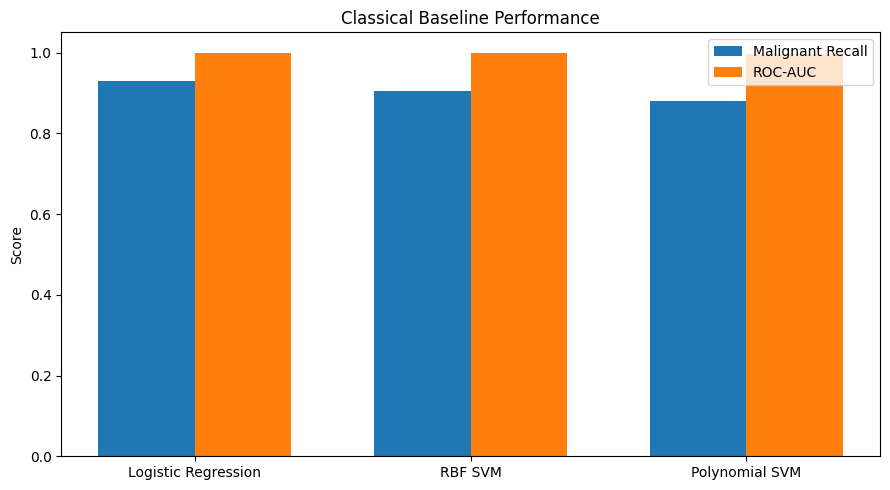

In [6]:

results_df.to_csv("classical_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(results_df))
width = 0.35

ax.bar(
    x - width/2,
    results_df["recall"],
    width,
    label="Malignant Recall"
)

ax.bar(
    x + width/2,
    results_df["roc_auc"],
    width,
    label="ROC-AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(results_df["model"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Classical Baseline Performance")
ax.legend()

plt.tight_layout()
plt.savefig("classical_comparison.png", dpi=200)
plt.show()


Run a sanity check

In [7]:

assert X_train.shape[1] == 4
assert X_test.shape[1] == 4
assert len(set(train_idx) & set(test_idx)) == 0
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert set(np.unique(y_train)) == {0, 1}
assert len(results_df) == 3

print("All basic checks passed.")


All basic checks passed.


Optimizing the Classification Threshold for Malignant Recall

In [8]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Already-tuned logistic regression pipeline
model = trained_models["Logistic Regression"]

# Out-of-fold scores using training data only
oof_scores = cross_val_predict(
    model,
    X_train_raw,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=-1
)

# Candidate thresholds from training predictions
thresholds = np.unique(oof_scores)

# Find threshold with >= 95% training recall,
# maximizing specificity among eligible thresholds
candidates = []

for threshold in thresholds:
    pred = (oof_scores >= threshold).astype(int)

    recall = recall_score(y_train, pred)
    tn, fp, fn, tp = confusion_matrix(
        y_train, pred
    ).ravel()

    specificity = tn / (tn + fp)

    if recall >= 0.95:
        candidates.append(
            (specificity, threshold, recall)
        )

if candidates:
    _, best_threshold, cv_recall = max(
        candidates,
        key=lambda x: (x[0], x[1])
    )
else:
    best_threshold = 0.0
    cv_recall = recall_score(
        y_train, (oof_scores >= 0).astype(int)
    )

# Final evaluation on held-out test data
test_scores = model.decision_function(X_test_raw)
test_pred = (test_scores >= best_threshold).astype(int)

print("Selected threshold:", best_threshold)
print("OOF malignant recall:", cv_recall)
print("Test malignant recall:",
      recall_score(y_test, test_pred))
print("Test precision:",
      precision_score(y_test, test_pred))
print("Test F1:",
      f1_score(y_test, test_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))


Selected threshold: -0.819612092758226
OOF malignant recall: 0.9529411764705882
Test malignant recall: 0.9761904761904762
Test precision: 0.9318181818181818
Test F1: 0.9534883720930233
Confusion matrix:
[[69  3]
 [ 1 41]]


Cost-Sensitive Classification Through Threshold Optimization

In [9]:

adjusted_result = pd.DataFrame([{
    "model": "Logistic Regression (Adjusted Threshold)",
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "roc_auc": roc_auc_score(y_test, test_scores),
    "false_negatives": int(
        confusion_matrix(y_test, test_pred)[1, 0]
    ),
    "false_positives": int(
        confusion_matrix(y_test, test_pred)[0, 1]
    )
}])

display(adjusted_result.round(4))
adjusted_result.to_csv(
    "threshold_adjusted_baseline.csv",
    index=False
)


,model,threshold,accuracy,precision,recall,f1,roc_auc,false_negatives,false_positives
0,Logistic Regression (Adjusted Threshold),-0.8196,0.9649,0.9318,0.9762,0.9535,0.998,1,3


Limited-Data Experiment Configuration

In [10]:

import os
import json
import time
from pathlib import Path

TRAIN_SIZES = [40, 80, 160]
SEEDS = [42, 123, 2026]

N_FEATURES = 4

OUTPUT_DIR = Path("limited_data")
OUTPUT_DIR.mkdir(exist_ok=True)

experiment_records = []

print("Training sizes:", TRAIN_SIZES)
print("Seeds:", SEEDS)
print("Output directory:", OUTPUT_DIR)


Training sizes: [40, 80, 160]
Seeds: [42, 123, 2026]
Output directory: limited_data


Generate Training Subsets

In [11]:

from sklearn.model_selection import train_test_split

def get_training_subset(n_samples, seed):
    # Only sample from the original training partition
    subset_idx, _ = train_test_split(
        train_idx,
        train_size=n_samples,
        stratify=y[train_idx],
        random_state=seed
    )

    return subset_idx

# Quick verification
for n in TRAIN_SIZES:
    subset_idx = get_training_subset(n, seed=42)

    assert len(subset_idx) == n
    assert len(set(subset_idx) & set(test_idx)) == 0

    labels = y[subset_idx]

    print(
        f"{n} samples:",
        f"{sum(labels == 1)} malignant,",
        f"{sum(labels == 0)} benign"
    )


40 samples: 15 malignant, 25 benign
80 samples: 30 malignant, 50 benign
160 samples: 60 malignant, 100 benign


Train Classical Models on Limited Data

In [12]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

limited_model_configs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10, 100]}
    ),
    "RBF SVM": (
        SVC(kernel="rbf"),
        {
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.1, 1, 10]
        }
    )
}

experiment_records = []

for n_samples in TRAIN_SIZES:
    for seed in SEEDS:

        print(f"\n--- Samples={n_samples}, Seed={seed} ---")

        subset_idx = get_training_subset(
            n_samples, seed
        )

        X_subset_raw = X[subset_idx]
        y_subset = y[subset_idx]

        # Shared quantum-compatible representation
        preprocessor = make_preprocessor(N_FEATURES)

        X_subset = preprocessor.fit_transform(
            X_subset_raw
        )
        X_test_processed = preprocessor.transform(
            X_test_raw
        )

        # Save data for Person B
        file_path = OUTPUT_DIR / (
            f"data_n{n_samples}_seed{seed}.npz"
        )

        np.savez(
            file_path,
            X_train=X_subset,
            X_test=X_test_processed,
            y_train=y_subset,
            y_test=y_test,
            train_idx=subset_idx,
            test_idx=test_idx
        )

        cv_subset = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=seed
        )

        for model_name, (estimator, grid) in (
            limited_model_configs.items()
        ):

            pipeline = Pipeline([
                ("preprocess", make_preprocessor(N_FEATURES)),
                ("model", estimator)
            ])

            search = GridSearchCV(
                pipeline,
                grid,
                cv=cv_subset,
                scoring="roc_auc",
                n_jobs=-1,
                refit=True
            )

            start = time.perf_counter()
            search.fit(X_subset_raw, y_subset)
            elapsed = time.perf_counter() - start

            best_model = search.best_estimator_

            predictions = best_model.predict(
                X_test_raw
            )
            scores = best_model.decision_function(
                X_test_raw
            )

            tn, fp, fn, tp = confusion_matrix(
                y_test, predictions
            ).ravel()

            experiment_records.append({
                "model": model_name,
                "n_samples": n_samples,
                "seed": seed,
                "accuracy": accuracy_score(
                    y_test, predictions
                ),
                "precision": precision_score(
                    y_test, predictions,
                    zero_division=0
                ),
                "recall": recall_score(
                    y_test, predictions
                ),
                "f1": f1_score(
                    y_test, predictions
                ),
                "roc_auc": roc_auc_score(
                    y_test, scores
                ),
                "false_negatives": int(fn),
                "false_positives": int(fp),
                "fit_and_tune_seconds": elapsed,
                "best_params": json.dumps(
                    search.best_params_
                )
            })

            print(
                model_name,
                "| Recall:",
                round(recall_score(
                    y_test, predictions
                ), 4),
                "| AUC:",
                round(roc_auc_score(
                    y_test, scores
                ), 4)
            )

limited_results = pd.DataFrame(
    experiment_records
)

limited_results.to_csv(
    OUTPUT_DIR / "classical_limited_results.csv",
    index=False
)

display(limited_results.round(4))



--- Samples=40, Seed=42 ---
Logistic Regression | Recall: 0.4762 | AUC: 0.994
RBF SVM | Recall: 0.7619 | AUC: 0.9934

--- Samples=40, Seed=123 ---
Logistic Regression | Recall: 0.881 | AUC: 0.9907
RBF SVM | Recall: 0.7381 | AUC: 0.9861

--- Samples=40, Seed=2026 ---
Logistic Regression | Recall: 0.9286 | AUC: 0.997
RBF SVM | Recall: 0.0 | AUC: 0.9947

--- Samples=80, Seed=42 ---
Logistic Regression | Recall: 0.7857 | AUC: 0.9957
RBF SVM | Recall: 0.0 | AUC: 0.9957

--- Samples=80, Seed=123 ---
Logistic Regression | Recall: 0.9286 | AUC: 0.997
RBF SVM | Recall: 0.7857 | AUC: 0.996

--- Samples=80, Seed=2026 ---
Logistic Regression | Recall: 0.881 | AUC: 0.995
RBF SVM | Recall: 0.8095 | AUC: 0.9815

--- Samples=160, Seed=42 ---
Logistic Regression | Recall: 0.9048 | AUC: 0.996
RBF SVM | Recall: 0.8333 | AUC: 0.9977

--- Samples=160, Seed=123 ---
Logistic Regression | Recall: 0.7857 | AUC: 0.9947
RBF SVM | Recall: 0.8571 | AUC: 0.997

--- Samples=160, Seed=2026 ---
Logistic Regression | 

,model,n_samples,seed,accuracy,precision,recall,f1,roc_auc,false_negatives,false_positives,fit_and_tune_seconds,best_params
0,Logistic Regression,40,42,0.8070,1.0000,0.4762,0.6452,0.9940,22,0,5.2324,"{""model__C"": 0.1}"
1,RBF SVM,40,42,0.9123,1.0000,0.7619,0.8649,0.9934,10,0,1.3861,"{""model__C"": 1, ""model__gamma"": 0.1}"
2,Logistic Regression,40,123,0.9474,0.9737,0.8810,0.9250,0.9907,5,1,0.4075,"{""model__C"": 10}"
3,RBF SVM,40,123,0.8947,0.9688,0.7381,0.8378,0.9861,11,1,1.0380,"{""model__C"": 10, ""model__gamma"": 0.1}"
4,Logistic Regression,40,2026,0.9649,0.9750,0.9286,0.9512,0.9970,3,1,0.5506,"{""model__C"": 10}"
5,RBF SVM,40,2026,0.6316,0.0000,0.0000,0.0000,0.9947,42,0,1.3220,"{""model__C"": 0.1, ""model__gamma"": 0.1}"
6,Logistic Regression,80,42,0.9211,1.0000,0.7857,0.8800,0.9957,9,0,0.8247,"{""model__C"": 1}"
7,RBF SVM,80,42,0.6316,0.0000,0.0000,0.0000,0.9957,42,0,2.2305,"{""model__C"": 0.1, ""model__gamma"": 0.1}"
8,Logistic Regression,80,123,0.9649,0.9750,0.9286,0.9512,0.9970,3,1,0.3658,"{""model__C"": 100}"
9,RBF SVM,80,123,0.9123,0.9706,0.7857,0.8684,0.9960,9,1,1.0366,"{""model__C"": 100, ""model__gamma"": 0.1}"


Aggregate Performance Across Seeds

In [13]:

summary = (
    limited_results
    .groupby(["model", "n_samples"])
    .agg(
        recall_mean=("recall", "mean"),
        recall_std=("recall", "std"),
        auc_mean=("roc_auc", "mean"),
        auc_std=("roc_auc", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
        fn_mean=("false_negatives", "mean")
    )
    .reset_index()
)

display(summary.round(4))

summary.to_csv(
    OUTPUT_DIR / "classical_summary.csv",
    index=False
)


,model,n_samples,recall_mean,recall_std,auc_mean,auc_std,f1_mean,f1_std,fn_mean
0,Logistic Regression,40,0.7619,0.2486,0.9939,0.0031,0.8405,0.1696,10.0000
1,Logistic Regression,80,0.8651,0.0727,0.9959,0.0010,0.9187,0.0360,5.6667
2,Logistic Regression,160,0.8016,0.0962,0.9960,0.0013,0.8839,0.0599,8.3333
3,RBF SVM,40,0.5000,0.4332,0.9914,0.0046,0.5676,0.4917,21.0000
4,RBF SVM,80,0.5317,0.4607,0.9911,0.0083,0.5877,0.5091,19.6667
5,RBF SVM,160,0.8571,0.0238,0.9974,0.0003,0.9191,0.0153,6.0000


Visualize Performance vs Training Size

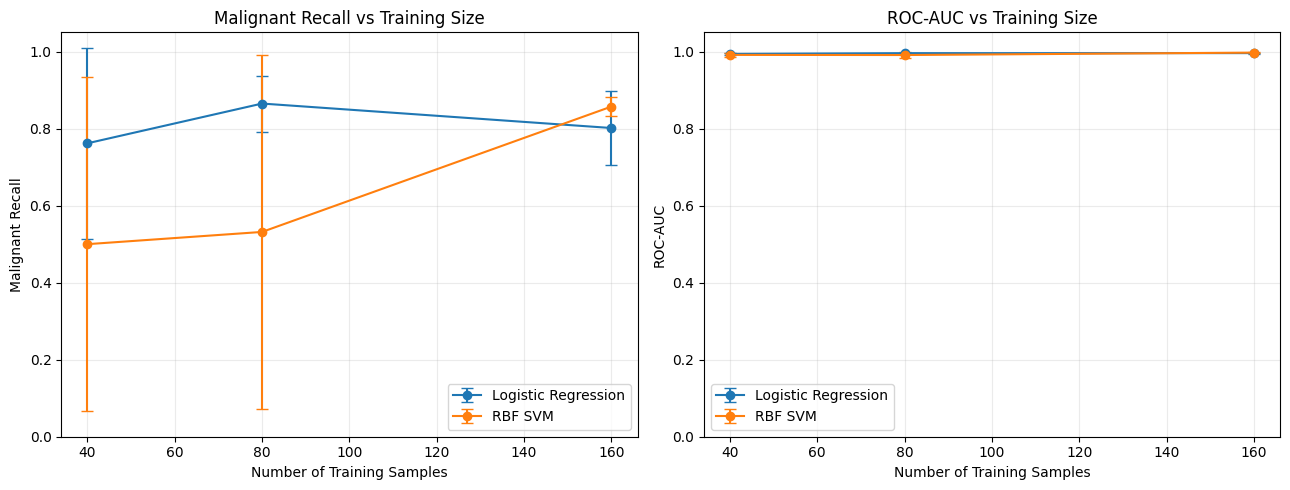

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = [
    ("recall", "Malignant Recall"),
    ("roc_auc", "ROC-AUC")
]

for ax, (metric, title) in zip(axes, metrics):

    for model_name in limited_results["model"].unique():

        subset = limited_results[
            limited_results["model"] == model_name
        ]

        grouped = subset.groupby("n_samples")[metric]

        means = grouped.mean()
        stds = grouped.std().fillna(0)

        ax.errorbar(
            means.index,
            means.values,
            yerr=stds.values,
            marker="o",
            capsize=4,
            label=model_name
        )

    ax.set_xlabel("Number of Training Samples")
    ax.set_ylabel(title)
    ax.set_title(title + " vs Training Size")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "classical_learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Verify Data Integrity

In [15]:

for n_samples in TRAIN_SIZES:
    for seed in SEEDS:

        path = OUTPUT_DIR / (
            f"data_n{n_samples}_seed{seed}.npz"
        )

        with np.load(path) as d:
            assert d["X_train"].shape == (
                n_samples, N_FEATURES
            )
            assert d["X_test"].shape == (
                len(test_idx), N_FEATURES
            )

            assert len(
                set(d["train_idx"]) &
                set(d["test_idx"])
            ) == 0

            assert np.isfinite(d["X_train"]).all()
            assert np.isfinite(d["X_test"]).all()

            assert np.array_equal(
                d["y_train"],
                y[d["train_idx"]]
            )

            assert np.array_equal(
                d["y_test"],
                y[d["test_idx"]]
            )

print("All 9 exported datasets passed validation.")


All 9 exported datasets passed validation.


Export Quantum-Compatible Datasets

In [16]:

import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "qbreast_limited_data",
    "zip",
    root_dir=".",
    base_dir="limited_data"
)

print("Created:", archive_path)

files.download(archive_path)


Created: /content/qbreast_limited_data.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Diagnose unstable SVM runs

In [17]:

diagnostic = limited_results[
    limited_results["model"] == "RBF SVM"
][[
    "n_samples",
    "seed",
    "recall",
    "precision",
    "roc_auc",
    "false_negatives",
    "false_positives",
    "best_params"
]]

display(
    diagnostic.sort_values(
        ["n_samples", "seed"]
    ).round(4)
)


,n_samples,seed,recall,precision,roc_auc,false_negatives,false_positives,best_params
1,40,42,0.7619,1.0000,0.9934,10,0,"{""model__C"": 1, ""model__gamma"": 0.1}"
3,40,123,0.7381,0.9688,0.9861,11,1,"{""model__C"": 10, ""model__gamma"": 0.1}"
5,40,2026,0.0000,0.0000,0.9947,42,0,"{""model__C"": 0.1, ""model__gamma"": 0.1}"
7,80,42,0.0000,0.0000,0.9957,42,0,"{""model__C"": 0.1, ""model__gamma"": 0.1}"
9,80,123,0.7857,0.9706,0.9960,9,1,"{""model__C"": 100, ""model__gamma"": 0.1}"
11,80,2026,0.8095,1.0000,0.9815,8,0,"{""model__C"": 1, ""model__gamma"": 1}"
13,160,42,0.8333,1.0000,0.9977,7,0,"{""model__C"": 1, ""model__gamma"": 0.1}"
15,160,123,0.8571,0.9730,0.9970,6,1,"{""model__C"": 10, ""model__gamma"": 0.1}"
17,160,2026,0.8810,1.0000,0.9974,5,0,"{""model__C"": 1, ""model__gamma"": ""scale""}"


Training-Only Threshold Calibration for RBF SVM

In [18]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

calibrated_records = []

for n_samples in TRAIN_SIZES:
    for seed in SEEDS:

        subset_idx = get_training_subset(n_samples, seed)
        X_sub = X[subset_idx]
        y_sub = y[subset_idx]

        cv_inner = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=seed
        )

        # Tune hyperparameters using training subset only
        pipeline = Pipeline([
            ("preprocess", make_preprocessor(N_FEATURES)),
            ("model", SVC(kernel="rbf"))
        ])

        search = GridSearchCV(
            pipeline,
            {
                "model__C": [0.1, 1, 10, 100],
                "model__gamma": ["scale", 0.1, 1, 10]
            },
            cv=cv_inner,
            scoring="roc_auc",
            n_jobs=-1,
            refit=True
        )

        search.fit(X_sub, y_sub)
        best_model = search.best_estimator_

        # Training-only out-of-fold decision scores
        oof_scores = cross_val_predict(
            clone(best_model),
            X_sub,
            y_sub,
            cv=cv_inner,
            method="decision_function",
            n_jobs=-1
        )

        # Select threshold for >= 95% training recall
        candidates = []

        for threshold in np.unique(oof_scores):

            pred = (oof_scores >= threshold).astype(int)

            recall = recall_score(y_sub, pred)

            tn, fp, fn, tp = confusion_matrix(
                y_sub, pred
            ).ravel()

            specificity = tn / (tn + fp)

            if recall >= 0.95:
                candidates.append(
                    (specificity, threshold)
                )

        if candidates:
            _, selected_threshold = max(
                candidates,
                key=lambda x: (x[0], x[1])
            )
        else:
            selected_threshold = 0.0

        # Evaluate on untouched test set
        scores = best_model.decision_function(X_test_raw)
        predictions = (
            scores >= selected_threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, predictions
        ).ravel()

        calibrated_records.append({
            "n_samples": n_samples,
            "seed": seed,
            "threshold": selected_threshold,
            "recall": recall_score(y_test, predictions),
            "precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_test, scores),
            "false_negatives": fn,
            "false_positives": fp,
            "best_C": search.best_params_["model__C"]
        })

calibrated_df = pd.DataFrame(calibrated_records)

display(calibrated_df.round(4))

calibrated_df.to_csv(
    OUTPUT_DIR / "rbf_threshold_adjusted.csv",
    index=False
)


,n_samples,seed,threshold,recall,precision,f1,roc_auc,false_negatives,false_positives,best_C
0,40,42,-0.7009,1.0000,0.8750,0.9333,0.9934,0,6,1.0
1,40,123,-0.4454,0.8810,0.9250,0.9024,0.9861,5,3,10.0
2,40,2026,-0.9259,0.9524,0.8889,0.9195,0.9947,2,5,0.1
3,80,42,-0.8991,1.0000,0.8750,0.9333,0.9957,0,6,0.1
4,80,123,-0.4735,0.8810,0.9737,0.9250,0.9960,5,1,100.0
5,80,2026,-0.1946,0.8810,0.9737,0.9250,0.9815,5,1,1.0
6,160,42,-0.3926,0.9762,0.9535,0.9647,0.9977,1,2,1.0
7,160,123,-0.4445,0.9762,0.9762,0.9762,0.9970,1,1,10.0
8,160,2026,-0.3210,0.9524,0.9756,0.9639,0.9974,2,1,1.0


Classical Baseline Comparison

In [19]:

# Default-threshold RBF results
default_rbf = limited_results[
    limited_results["model"] == "RBF SVM"
].copy()

default_rbf["threshold_method"] = "Default"

# Adjusted-threshold RBF results
adjusted_rbf = calibrated_df.copy()
adjusted_rbf["threshold_method"] = "Adjusted"

columns = [
    "n_samples", "seed", "threshold_method",
    "recall", "precision", "f1", "roc_auc",
    "false_negatives", "false_positives"
]

comparison = pd.concat([
    default_rbf[columns],
    adjusted_rbf[columns]
], ignore_index=True)

comparison_summary = (
    comparison
    .groupby(["n_samples", "threshold_method"])
    [["recall", "precision", "f1", "roc_auc"]]
    .agg(["mean", "std"])
)

display(comparison_summary.round(4))

comparison.to_csv(
    OUTPUT_DIR / "threshold_comparison.csv",
    index=False
)


recall         precision              f1          \
                              mean     std      mean     std    mean     std   
n_samples threshold_method                                                     
40        Adjusted          0.9444  0.0599    0.8963  0.0258  0.9184  0.0155   
          Default           0.5000  0.4332    0.6562  0.5685  0.5676  0.4917   
80        Adjusted          0.9206  0.0687    0.9408  0.0570  0.9278  0.0048   
          Default           0.5317  0.4607    0.6569  0.5690  0.5877  0.5091   
160       Adjusted          0.9683  0.0137    0.9684  0.0129  0.9683  0.0069   
          Default           0.8571  0.0238    0.9910  0.0156  0.9191  0.0153   

                           roc_auc          
                              mean     std  
n_samples threshold_method                  
40        Adjusted          0.9914  0.0046  
          Default           0.9914  0.0046  
80        Adjusted          0.9911  0.0083  
          Default           0.9911  0.0083  
160       Adjusted          0.9974  0.0003  
          Default           0.9974  0.0003

Visualize Threshold Effects

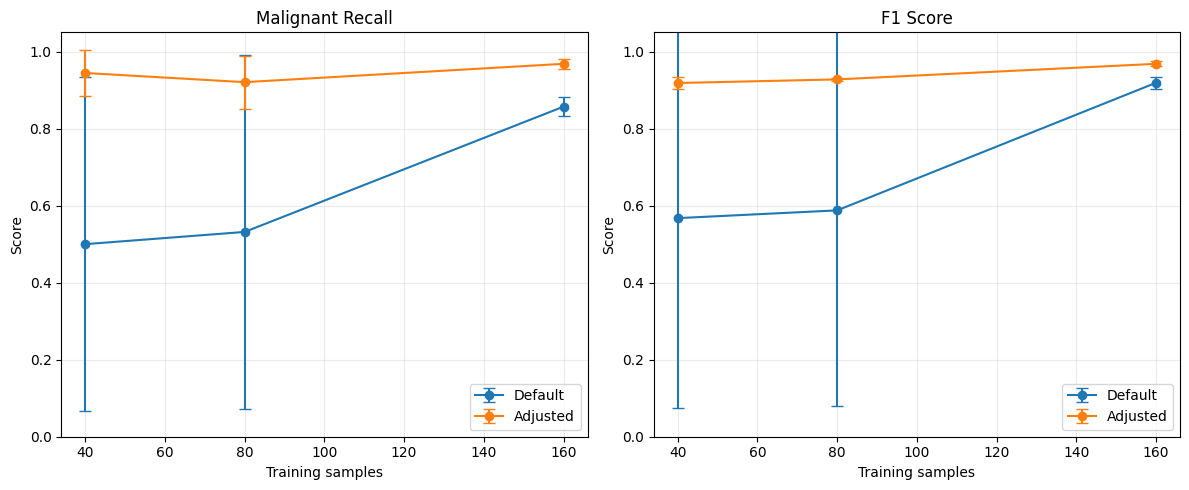

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title in zip(
    axes,
    ["recall", "f1"],
    ["Malignant Recall", "F1 Score"]
):
    for method in ["Default", "Adjusted"]:
        subset = comparison[
            comparison["threshold_method"] == method
        ]

        grouped = subset.groupby("n_samples")[metric]

        ax.errorbar(
            grouped.mean().index,
            grouped.mean().values,
            yerr=grouped.std().values,
            marker="o",
            capsize=4,
            label=method
        )

    ax.set_title(title)
    ax.set_xlabel("Training samples")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "threshold_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


Quantum Results Integration Template

In [21]:

quantum_template = pd.DataFrame([
    {
        "model": "Quantum Kernel SVM",
        "n_samples": n,
        "seed": seed,
        "recall": np.nan,
        "precision": np.nan,
        "f1": np.nan,
        "roc_auc": np.nan,
        "false_negatives": np.nan,
        "false_positives": np.nan,
        "kernel_seconds": np.nan,
        "feature_map": "",
        "threshold_method": ""
    }
    for n in TRAIN_SIZES
    for seed in SEEDS
])

quantum_template.to_csv(
    OUTPUT_DIR / "quantum_results_template.csv",
    index=False
)

display(quantum_template)


,model,n_samples,seed,recall,precision,f1,roc_auc,false_negatives,false_positives,kernel_seconds,feature_map,threshold_method
0,Quantum Kernel SVM,40,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
1,Quantum Kernel SVM,40,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
2,Quantum Kernel SVM,40,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
3,Quantum Kernel SVM,80,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
4,Quantum Kernel SVM,80,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
5,Quantum Kernel SVM,80,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
6,Quantum Kernel SVM,160,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
7,Quantum Kernel SVM,160,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,
8,Quantum Kernel SVM,160,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,


Package Classical Benchmark

In [22]:

import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "qbreast_person_a",
    "zip",
    root_dir=".",
    base_dir="limited_data"
)

files.download(archive_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>